# 06. Country Clustering Based on Reported Drug-Class Composition

## Research question

Can countries be grouped according to the composition of their reported
drug seizure records?

The analysis uses each country's percentage distribution across drug
classes, rather than raw record counts. K-Means is used to identify
similar profiles, and PCA provides a two-dimensional visualization.

## Methodological choices

- Main period: 2011–2025; partial 2026 is excluded.
- Country identity: ISO3.
- Minimum inclusion threshold: 500 records over the analysis period.
- `Unclassified` records are retained as a category.
- Cluster numbers are arbitrary identifiers. Descriptive labels are
  derived from each cluster's average drug-class profile.
- Clusters describe similarity in reported records, not national drug
  markets, trafficking routes, or geographical proximity.

## 1. Import libraries and connect to DuckDB

In [2]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

current_path = Path.cwd()

# Locate the project root by searching for data/processed.
# This follows the same approach used in notebook 02.
PROJECT_ROOT = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "data" / "processed").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing data/processed. "
        "Please check where Jupyter is running."
    )

# Define the main project directories
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Database path
DB_PATH = PROCESSED_DIR / "seizure_signals.duckdb"

# Create output directories if they do not exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check that the database exists
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}"
    )

print("Project root:", PROJECT_ROOT)
print("Database:", DB_PATH)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

Project root: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals
Database: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\data\processed\seizure_signals.duckdb
Results directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results
Figures directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\figures


In [3]:
# Connect to the existing DuckDB database.
# read_only=True prevents accidental modifications.
con = duckdb.connect(
    database=str(DB_PATH),
    read_only=True
)

print("Connected to DuckDB successfully.")

Connected to DuckDB successfully.


## 2. Extract country-level drug profiles

In [4]:
# Aggregate reported records by ISO3 and drug class.
# The LEFT JOIN preserves records without a matched drug classification.

query = """
SELECT
    dc.ISO3,
    dc.country_name,
    COALESCE(dd.drug_class, 'Unclassified') AS drug_class,
    COUNT(*) AS total_records
FROM fact_seizure f
JOIN dim_country dc
    ON f.country_key = dc.country_key
LEFT JOIN dim_drug dd
    ON f.drug_key = dd.drug_key
WHERE f.source_year BETWEEN 2011 AND 2025
GROUP BY
    dc.ISO3,
    dc.country_name,
    COALESCE(dd.drug_class, 'Unclassified')
ORDER BY dc.ISO3, drug_class
"""

country_drugs = con.execute(query).df()

print("Countries:", country_drugs["ISO3"].nunique())
print("Drug classes:", country_drugs["drug_class"].nunique())
display(country_drugs.head())

Countries: 147
Drug classes: 14


,ISO3,country_name,drug_class,total_records
0,AFG,Afghanistan,Amphetamine-type stimulants (excluding ecstasy),1907
1,AFG,Afghanistan,Cannabis-type (excluding synthetic cannabinoids),4141
2,AFG,Afghanistan,Opioids,7304
3,AFG,Afghanistan,Other chemicals,8
4,AFG,Afghanistan,Other drugs/substances,5


## 3. Build country drug-composition profiles

In [5]:
# Pivot to a country x drug-class matrix.
country_matrix = country_drugs.pivot_table(
    index="ISO3",
    columns="drug_class",
    values="total_records",
    aggfunc="sum",
    fill_value=0
)

# Preserve country names separately for reporting and mapping.
country_names = (
    country_drugs[["ISO3", "country_name"]]
    .drop_duplicates("ISO3")
    .set_index("ISO3")["country_name"]
)

country_totals = country_matrix.sum(axis=1)

MIN_RECORDS = 500
eligible_iso3 = country_totals[country_totals >= MIN_RECORDS].index
country_matrix = country_matrix.loc[eligible_iso3].copy()

# Convert counts into within-country percentages.
# Each country profile sums to 100%.
country_profiles = country_matrix.div(
    country_matrix.sum(axis=1),
    axis=0
) * 100

print("Countries in source period:", len(country_totals))
print("Countries retained:", len(country_profiles))
print("Countries excluded:", len(country_totals) - len(country_profiles))
print("Minimum record threshold:", MIN_RECORDS)

display(country_profiles.head())

Countries in source period: 147
Countries retained: 84
Countries excluded: 63
Minimum record threshold: 500


drug_class,Amphetamine-type stimulants (excluding ecstasy),Cannabis-type (excluding synthetic cannabinoids),Cocaine-type,Hallucinogens,New psychoactive substances,Non-specified psychotropic substances,Opioids,Other chemicals,Other drugs/substances,Precursors,Sedatives and Tranquillizers,Solvents and Inhalants,Unclassified,“Ecstasy”-type substances
ISO3,,,,,,,,,,,,,,
AFG,13.652635,29.646334,0.000000,0.000000,0.000000,0.000000,52.290951,0.057274,0.035796,2.047537,0.000000,0.000000,2.269473,0.000000
ARM,5.972435,23.277182,3.675345,2.603369,1.225115,0.612557,33.384380,0.000000,9.954058,1.071975,16.079632,0.000000,0.153139,1.990812
AUT,11.312988,38.807665,18.878637,2.029808,0.738112,0.000000,15.642300,0.056778,0.099361,0.369056,3.860894,0.014194,0.681334,7.508872
AZE,16.565433,26.670348,0.607399,0.000000,0.000000,0.000000,50.745445,0.000000,1.104362,0.496963,3.257869,0.000000,0.000000,0.552181
BEL,3.511875,20.212228,34.360788,1.263264,14.527539,0.000000,5.381506,0.202122,0.252653,2.905508,0.960081,0.101061,0.025265,16.296109


## 4. Determine the number of clusters

C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than 

,k,inertia,silhouette
0,2,97520.059,0.252
1,3,77168.711,0.261
2,4,63305.122,0.284
3,5,49118.572,0.322
4,6,40582.531,0.330
5,7,36570.024,0.321
6,8,32660.178,0.310


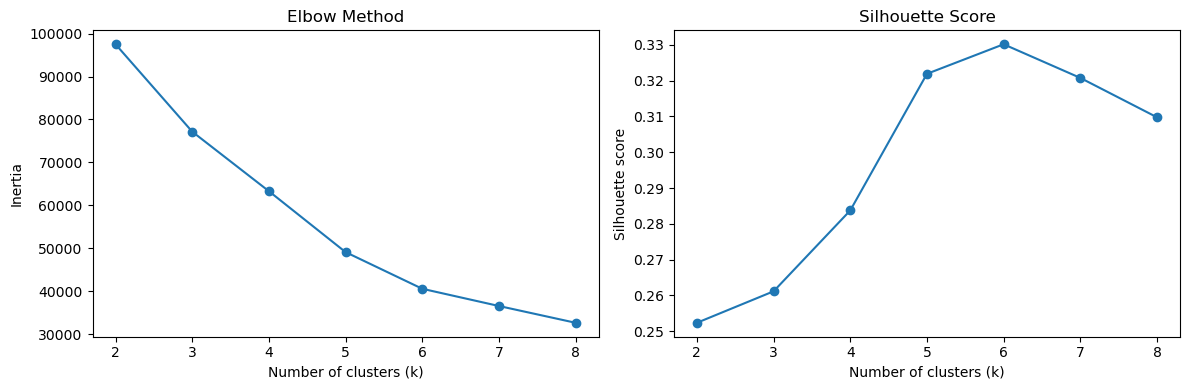

In [15]:
# Compare candidate K values using inertia and silhouette score.
# Silhouette score is only a diagnostic; substantive interpretability
# should also inform the final choice.

max_k = min(8, len(country_profiles) - 1)
if max_k < 2:
    raise ValueError("Not enough eligible countries for clustering.")

k_values = range(2, max_k + 1)
inertias = []
silhouette_scores = []

for k in k_values:
    candidate = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = candidate.fit_predict(country_profiles)

    inertias.append(candidate.inertia_)
    silhouette_scores.append(
        silhouette_score(country_profiles, labels)
    )

k_diagnostics = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouette_scores
})
display(k_diagnostics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_diagnostics["k"], k_diagnostics["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    k_diagnostics["k"],
    k_diagnostics["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "clustering_k_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Fit the final K-Means model

In [7]:
# The original analysis used six clusters. Keep k=6 for comparability,
# provided there are enough eligible countries. Reconsider this choice
# if the diagnostic results or cluster profiles suggest otherwise.

FINAL_K = 6

if len(country_profiles) <= FINAL_K:
    raise ValueError("There are not enough countries to fit six clusters.")

kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

cluster_assignments = pd.Series(
    kmeans.fit_predict(country_profiles),
    index=country_profiles.index,
    name="cluster"
)

# Do not add the cluster column to country_profiles: keep the feature
# matrix numeric and separate from cluster labels.
cluster_sizes = cluster_assignments.value_counts().sort_index()
cluster_profiles = country_profiles.groupby(cluster_assignments).mean()

print("Countries per cluster:")
display(cluster_sizes.rename("countries"))

print("Average drug-class composition by cluster (%):")
display(cluster_profiles.round(2))

Countries per cluster:


C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


cluster
0    12
1    14
2     8
3     5
4    26
5    19
Name: countries, dtype: int64

Average drug-class composition by cluster (%):


drug_class,Amphetamine-type stimulants (excluding ecstasy),Cannabis-type (excluding synthetic cannabinoids),Cocaine-type,Hallucinogens,New psychoactive substances,Non-specified psychotropic substances,Opioids,Other chemicals,Other drugs/substances,Precursors,Sedatives and Tranquillizers,Solvents and Inhalants,Unclassified,“Ecstasy”-type substances
cluster,,,,,,,,,,,,,,
0,0.65,38.38,53.69,0.27,1.26,0.00,2.36,0.02,0.24,0.31,0.14,0.01,0.27,2.41
1,7.91,37.31,2.38,0.44,3.29,0.16,37.69,0.05,1.59,0.88,2.52,0.01,4.18,1.58
2,51.07,21.83,4.04,0.41,7.09,0.02,6.06,0.00,1.76,0.40,2.10,0.00,0.58,4.63
3,4.39,17.68,2.41,2.12,58.91,0.13,3.34,0.00,1.65,0.45,0.49,0.00,5.90,2.53
4,10.64,39.42,12.21,1.44,8.54,1.64,9.98,0.05,4.30,1.64,4.24,0.04,1.05,4.81
5,1.44,74.90,16.23,0.63,1.02,0.03,2.09,0.01,1.61,0.44,0.71,0.01,0.08,0.81


## 6. Derive descriptive cluster profiles

In [8]:
# Cluster IDs are arbitrary. Derive a descriptive label from the
# highest average drug-class share in each cluster.
# If no class exceeds 40%, call it a mixed profile.

cluster_labels = {}
cluster_summary_rows = []

for cluster_id, profile in cluster_profiles.iterrows():
    dominant_class = profile.idxmax()
    dominant_share = float(profile.max())

    if dominant_share < 40:
        label = "Mixed profile"
    else:
        label = f"{dominant_class}-oriented"

    cluster_labels[cluster_id] = label
    cluster_summary_rows.append({
        "cluster": cluster_id,
        "cluster_label": label,
        "countries": int(cluster_sizes.loc[cluster_id]),
        "dominant_class": dominant_class,
        "dominant_class_share_pct": dominant_share
    })

cluster_summary = pd.DataFrame(cluster_summary_rows)
display(cluster_summary.round(2))

,cluster,cluster_label,countries,dominant_class,dominant_class_share_pct
0,0,Cocaine-type-oriented,12,Cocaine-type,53.69
1,1,Mixed profile,14,Opioids,37.69
2,2,Amphetamine-type stimulants (excluding ecstasy...,8,Amphetamine-type stimulants (excluding ecstasy),51.07
3,3,New psychoactive substances-oriented,5,New psychoactive substances,58.91
4,4,Mixed profile,26,Cannabis-type (excluding synthetic cannabinoids),39.42
5,5,Cannabis-type (excluding synthetic cannabinoid...,19,Cannabis-type (excluding synthetic cannabinoids),74.90


## 7. Identify countries in each cluster

In [9]:
cluster_members = pd.DataFrame({
    "ISO3": cluster_assignments.index,
    "cluster": cluster_assignments.values
})

cluster_members["country_name"] = (
    cluster_members["ISO3"].map(country_names)
)
cluster_members["cluster_label"] = (
    cluster_members["cluster"].map(cluster_labels)
)

cluster_members = cluster_members.sort_values(
    ["cluster", "country_name"]
)

display(cluster_members)

for cluster_id in sorted(cluster_assignments.unique()):
    subset = cluster_members.loc[
        cluster_members["cluster"] == cluster_id,
        "country_name"
    ].dropna().tolist()

    print(
        f"\\nCluster {cluster_id} — {cluster_labels[cluster_id]} "
        f"({len(subset)} countries)"
    )
    print(", ".join(subset))

,ISO3,cluster,country_name,cluster_label
4,BEL,0,Belgium,Cocaine-type-oriented
9,BOL,0,Bolivia (Plurinational State of),Cocaine-type-oriented
10,BRA,0,Brazil,Cocaine-type-oriented
15,COL,0,Colombia,Cocaine-type-oriented
22,DOM,0,Dominican Republic,Cocaine-type-oriented
...,...,...,...,...
44,LCA,5,Saint Lucia,Cannabis-type (excluding synthetic cannabinoid...
80,VCT,5,Saint Vincent and the Grenadines,Cannabis-type (excluding synthetic cannabinoid...
25,ESP,5,Spain,Cannabis-type (excluding synthetic cannabinoid...
81,VEN,5,Venezuela (Bolivarian Republic of),Cannabis-type (excluding synthetic cannabinoid...


\nCluster 0 — Cocaine-type-oriented (12 countries)
Belgium, Bolivia (Plurinational State of), Brazil, Colombia, Dominican Republic, Ecuador, Panama, Paraguay, Peru, Portugal, Suriname, Uruguay
\nCluster 1 — Mixed profile (14 countries)
Afghanistan, Armenia, Azerbaijan, Côte d'Ivoire, India, Kazakhstan, Kenya, Maldives, Mauritius, Myanmar, Pakistan, Sri Lanka, Tajikistan, Uzbekistan
\nCluster 2 — Amphetamine-type stimulants (excluding ecstasy)-oriented (8 countries)
Jordan, Macao SAR, China, Malaysia, Mexico, Philippines, Republic of Korea, Syrian Arab Republic, Thailand
\nCluster 3 — New psychoactive substances-oriented (5 countries)
Belarus, Georgia, Hungary, Latvia, Lithuania
\nCluster 4 — Mixed profile (26 countries)
Algeria, Austria, Bosnia and Herzegovina, Bulgaria, Canada, China, Hong Kong SAR, Croatia, Czechia, Finland, Germany, Greece, Libya, Luxembourg, Malta, Morocco, New Zealand, Nigeria, Poland, Republic of Moldova, Romania, Russian Federation, Serbia, South Africa, Sweden,

## 8. PCA visualization

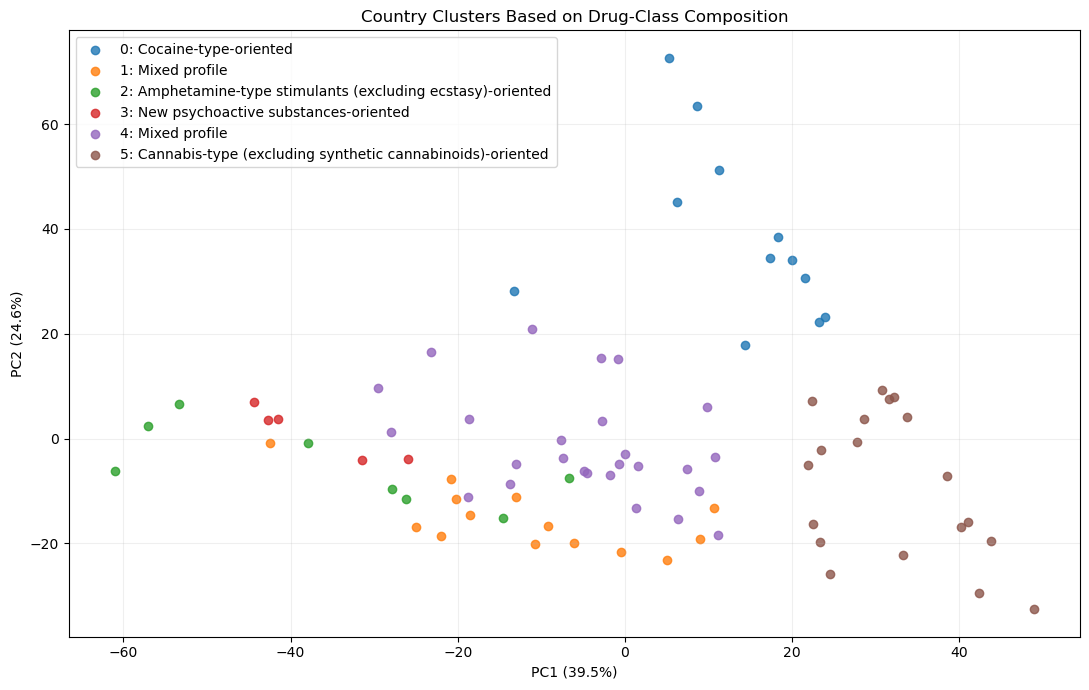

Variance explained by first two components: 64.05 %


In [14]:
# PCA is used only to visualize the country profiles in two dimensions.
# It does not determine the K-Means clusters.

pca = PCA(n_components=2)
X_pca = pca.fit_transform(country_profiles)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=country_profiles.index
)
pca_df["cluster"] = cluster_assignments
pca_df["cluster_label"] = pca_df["cluster"].map(cluster_labels)
pca_df["country_name"] = pca_df.index.map(country_names)

plt.figure(figsize=(11, 7))

for cluster_id in sorted(cluster_assignments.unique()):
    subset = pca_df[pca_df["cluster"] == cluster_id]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"{cluster_id}: {cluster_labels[cluster_id]}",
        alpha=0.8
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("Country Clusters Based on Drug-Class Composition")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "country_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

## 9. Interactive HTML map

In [11]:
# Map cluster assignments using ISO3, not country names.
# Plotly is required. If not installed, run in a separate cell:
# %pip install plotly

import plotly.express as px

cluster_map = cluster_members.copy()
cluster_map["cluster"] = cluster_map["cluster"].astype(str)
cluster_map["cluster_label"] = cluster_map["cluster"].astype(int).map(
    cluster_labels
)

fig = px.choropleth(
    cluster_map,
    locations="ISO3",
    color="cluster_label",
    hover_name="country_name",
    hover_data={
        "ISO3": True,
        "cluster": True,
        "cluster_label": True
    },
    locationmode="ISO-3",
    projection="natural earth",
    title="Country Clusters Based on Reported Drug-Class Composition"
)

fig.update_layout(
    legend_title="Cluster profile",
    geo=dict(
        showframe=False,
        showcoastlines=True,
        showland=True
    ),
    height=650
)

fig.show()

fig.write_html(FIGURES_DIR / "country_clusters_map.html")
print("Map saved:", FIGURES_DIR / "country_clusters_map.html")

Map saved: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\figures\country_clusters_map.html


## 10. Save clustering outputs

In [12]:
# Save cluster membership, average profiles, diagnostics, and PCA scores.
cluster_members.to_csv(
    RESULTS_DIR / "country_cluster_assignments.csv",
    index=False
)
cluster_profiles.to_csv(
    RESULTS_DIR / "country_cluster_profiles.csv"
)
cluster_summary.to_csv(
    RESULTS_DIR / "country_cluster_summary.csv",
    index=False
)
k_diagnostics.to_csv(
    RESULTS_DIR / "country_clustering_k_diagnostics.csv",
    index=False
)
pca_df.to_csv(
    RESULTS_DIR / "country_clusters_pca_coordinates.csv"
)

print("Clustering outputs saved to:", RESULTS_DIR)

Clustering outputs saved to: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results


## Conclusions

Update this section after running the notebook. Report:
- the number of countries retained after the 500-record threshold;
- the chosen number of clusters and the diagnostic evidence supporting it;
- the size and dominant drug-class profile of each cluster;
- the silhouette score and PCA variance explained;
- any countries or clusters that require cautious interpretation.

Cluster membership describes similarities in reported seizure-record
composition. It does not establish definitive characteristics of
national drug markets or trafficking patterns.

In [13]:
con.close()
print('DuckDB connection closed.')

DuckDB connection closed.
